# Progressão Geométrica (PG)
### Continuação do estudo de sequências numéricas

No notebook anterior, estudamos a **Progressão Aritmética (PA)**, em que somamos uma diferença constante chamada razão.

Agora vamos estudar a **Progressão Geométrica (PG)**. Em uma PG, cada termo é obtido multiplicando o termo anterior por um mesmo número, chamado **razão** e representado por $q$.

Por exemplo:

$$
(2,\ 6,\ 18,\ 54,\ 162,\ldots)
$$

Cada termo é o anterior multiplicado por $3$. Logo, a razão é $q=3$.

### O que vamos aprender
- identificar a razão de uma PG;
- reconhecer PGs crescentes, decrescentes, constantes e alternantes;
- calcular termos com a fórmula do termo geral;
- calcular a soma dos primeiros termos;
- comparar visualmente o crescimento de uma PA e de uma PG.

> **Pré-requisito:** este notebook parte do princípio de que você já conhece as células Markdown e Code do Jupyter, a execução de código Python e os gráficos básicos com Matplotlib.

## 1. A diferença entre PA e PG

Na PA, a diferença entre termos consecutivos é constante. Na PG, o **quociente** entre um termo e o anterior é constante.

| Progressão | Regra | Exemplo | Razão |
|---|---|---|---|
| PA | Soma uma diferença fixa | $2, 5, 8, 11, \ldots$ | $r=3$ |
| PG | Multiplica por um fator fixo | $2, 6, 18, 54, \ldots$ | $q=3$ |

Para uma PG, quando o termo anterior é diferente de zero:

$$
\boxed{q=\frac{a_n}{a_{n-1}}}
$$

Por exemplo, na sequência $(2,6,18,54)$:

$$
q=\frac{6}{2}=3,\qquad q=\frac{18}{6}=3
$$

O mesmo fator se repete a cada passo.

In [1]:
# @title
termos = [2, 6, 18, 54, 162]

razoes = [termos[i] / termos[i - 1] for i in range(1, len(termos))]

print("Termos:", termos)
print("Quocientes entre termos consecutivos:", razoes)
print("Razão constante?", all(abs(q - razoes[0]) < 1e-10 for q in razoes))
print("Razão da PG:", razoes[0])

Termos: [2, 6, 18, 54, 162]
Quocientes entre termos consecutivos: [3.0, 3.0, 3.0, 3.0]
Razão constante? True
Razão da PG: 3.0


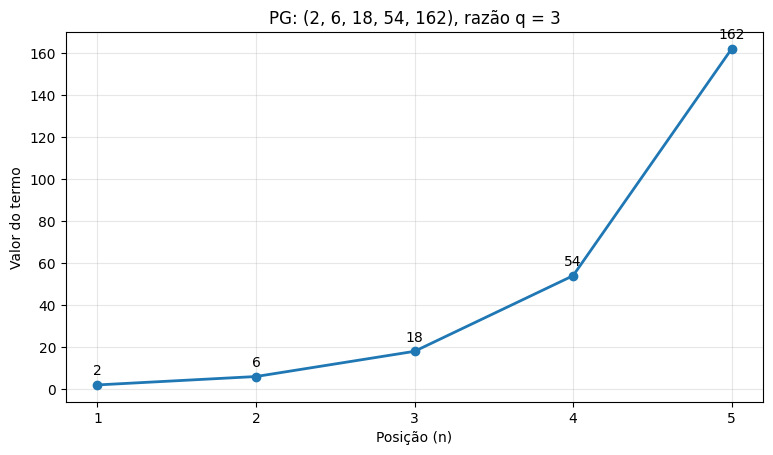

In [2]:
# @title
import matplotlib.pyplot as plt
import numpy as np

plt.rcParams["figure.figsize"] = (9, 4.8)
plt.rcParams["axes.grid"] = True
plt.rcParams["grid.alpha"] = 0.3

posicoes = np.arange(1, len(termos) + 1)

plt.figure()
plt.plot(posicoes, termos, marker="o", linewidth=2)
for n, a in zip(posicoes, termos):
    plt.annotate(str(a), (n, a), xytext=(0, 7),
                 textcoords="offset points", ha="center")
plt.xticks(posicoes)
plt.xlabel("Posição (n)")
plt.ylabel("Valor do termo")
plt.title("PG: (2, 6, 18, 54, 162), razão q = 3")
plt.show()

## 2. Tipos de PG

O comportamento de uma PG depende do primeiro termo e da razão. Nos exemplos mais comuns:

- **Crescente:** os termos aumentam em sequência, como $2,6,18,54,\ldots$.
- **Decrescente:** os termos diminuem em direção a zero, como $64,32,16,8,\ldots$.
- **Constante:** os termos permanecem iguais, como $5,5,5,5,\ldots$, quando $q=1$.
- **Alternante:** os sinais dos termos alternam, como $2,-4,8,-16,\ldots$, quando $q<0$.

A classificação exige atenção: por exemplo, uma PG com $q>1$ não é necessariamente crescente se começar com um termo negativo. Observe também que $q=0$ produz uma sequência como $5,0,0,0,\ldots$, que não é constante.

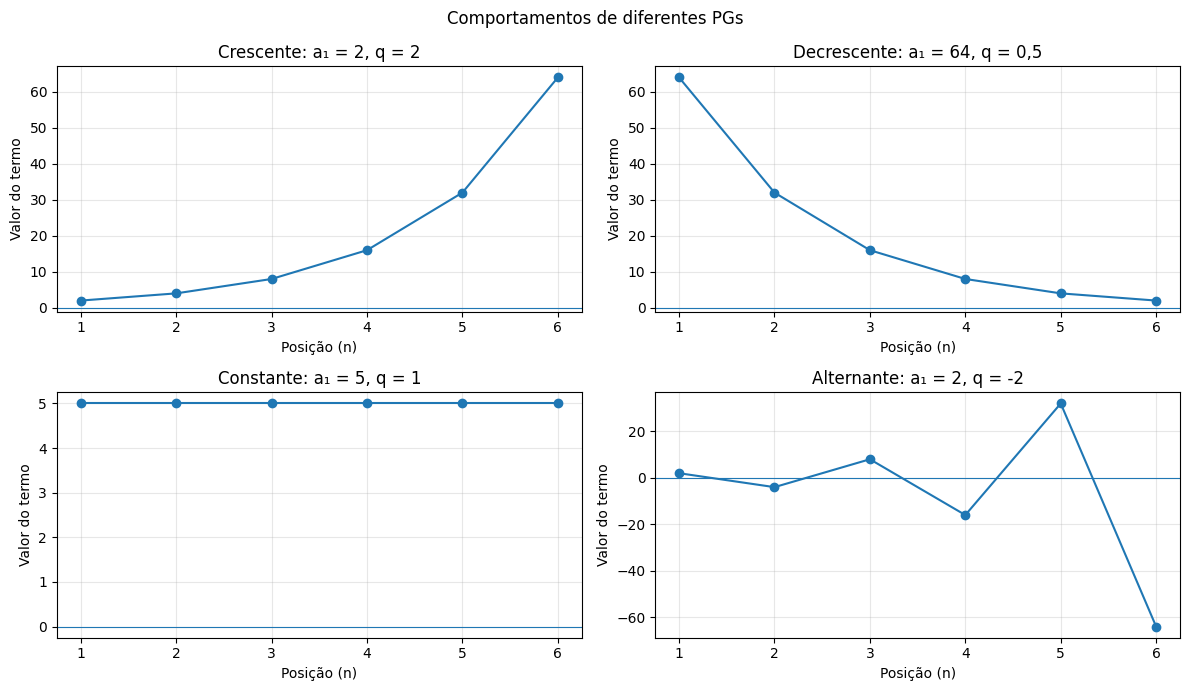

In [3]:
# @title
exemplos = [
    {"nome": "Crescente: a₁ = 2, q = 2", "a1": 2, "q": 2},
    {"nome": "Decrescente: a₁ = 64, q = 0,5", "a1": 64, "q": 0.5},
    {"nome": "Constante: a₁ = 5, q = 1", "a1": 5, "q": 1},
    {"nome": "Alternante: a₁ = 2, q = -2", "a1": 2, "q": -2},
]

n = np.arange(1, 7)
fig, eixos = plt.subplots(2, 2, figsize=(12, 7))

for ax, exemplo in zip(eixos.flat, exemplos):
    valores = exemplo["a1"] * exemplo["q"] ** (n - 1)
    ax.plot(n, valores, marker="o")
    ax.axhline(0, linewidth=0.8)
    ax.set_title(exemplo["nome"])
    ax.set_xlabel("Posição (n)")
    ax.set_ylabel("Valor do termo")
    ax.set_xticks(n)

fig.suptitle("Comportamentos de diferentes PGs")
plt.tight_layout()
plt.show()

## 3. Fórmula do termo geral

Na PA, usamos $a_n=a_1+(n-1)r$. Na PG, a operação repetida é a multiplicação, então usamos:

$$
\boxed{a_n=a_1\cdot q^{n-1}}
$$

- $a_n$: termo que queremos encontrar;
- $a_1$: primeiro termo;
- $q$: razão da PG;
- $n$: posição do termo.

### Exemplo

Qual é o 6.º termo da PG $(3,6,12,24,\ldots)$?

Aqui, $a_1=3$, $q=2$ e $n=6$:

$$
a_6=3\cdot2^{6-1}=3\cdot32=\boxed{96}
$$

O expoente é $n-1$, porque o primeiro termo ainda não recebeu nenhuma multiplicação pela razão.

In [4]:
# @title
a1 = 3
q = 2
n_alvo = 6

an = a1 * q ** (n_alvo - 1)
print(f"O termo a_{n_alvo} é {an}.")

O termo a_6 é 96.


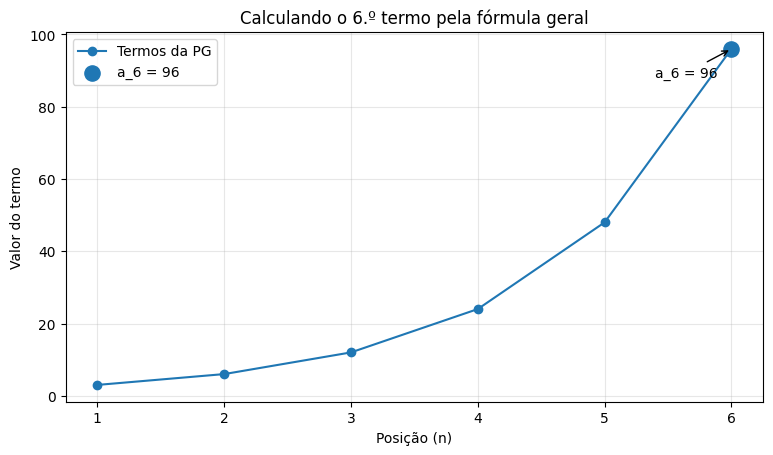

In [5]:
# @title
n = np.arange(1, n_alvo + 1)
valores = a1 * q ** (n - 1)

plt.figure()
plt.plot(n, valores, marker="o", label="Termos da PG")
plt.scatter([n_alvo], [an], s=120, label=f"a_{n_alvo} = {an}", zorder=3)
plt.annotate(f"a_{n_alvo} = {an}", (n_alvo, an),
             xytext=(-55, -20), textcoords="offset points",
             arrowprops={"arrowstyle": "->"})
plt.xticks(n)
plt.xlabel("Posição (n)")
plt.ylabel("Valor do termo")
plt.title("Calculando o 6.º termo pela fórmula geral")
plt.legend()
plt.show()

## 4. Comparando o crescimento de PA e PG

Uma PA com razão positiva cresce adicionando sempre o mesmo valor. Uma PG com razão maior que $1$, partindo de um primeiro termo positivo, cresce multiplicando por um fator fixo.

Vamos comparar as sequências:

- PA: $a_1=2$, $r=3$;
- PG: $a_1=2$, $q=3$.

As duas começam em $2$, mas o crescimento se comporta de forma diferente. Para tornar a comparação clara, veremos os valores em escala comum e, depois, em escala logarítmica.

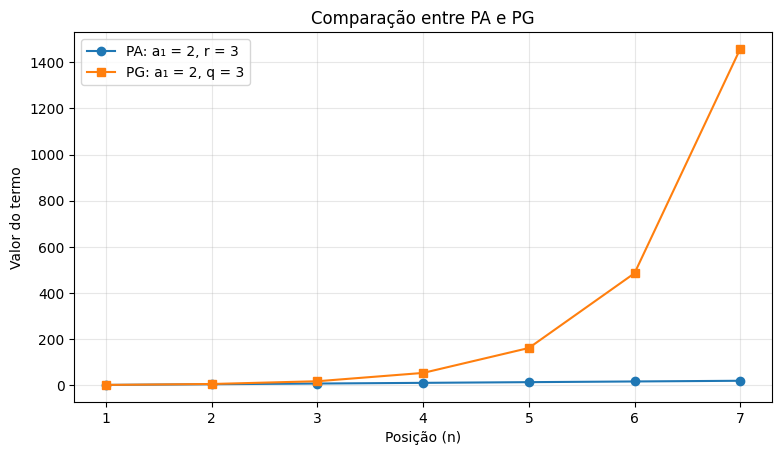

PA: [2, 5, 8, 11, 14, 17, 20]
PG: [2, 6, 18, 54, 162, 486, 1458]


In [6]:
# @title
n = np.arange(1, 8)

termos_pa = 2 + (n - 1) * 3
termos_pg = 2 * 3 ** (n - 1)

plt.figure()
plt.plot(n, termos_pa, marker="o", label="PA: a₁ = 2, r = 3")
plt.plot(n, termos_pg, marker="s", label="PG: a₁ = 2, q = 3")
plt.xticks(n)
plt.xlabel("Posição (n)")
plt.ylabel("Valor do termo")
plt.title("Comparação entre PA e PG")
plt.legend()
plt.show()

print("PA:", termos_pa.tolist())
print("PG:", termos_pg.tolist())

Na escala comum, os termos da PG rapidamente ficam muito maiores que os da PA. Uma escala logarítmica ajuda a visualizar valores muito diferentes entre si. Ela só aceita valores positivos neste exemplo.

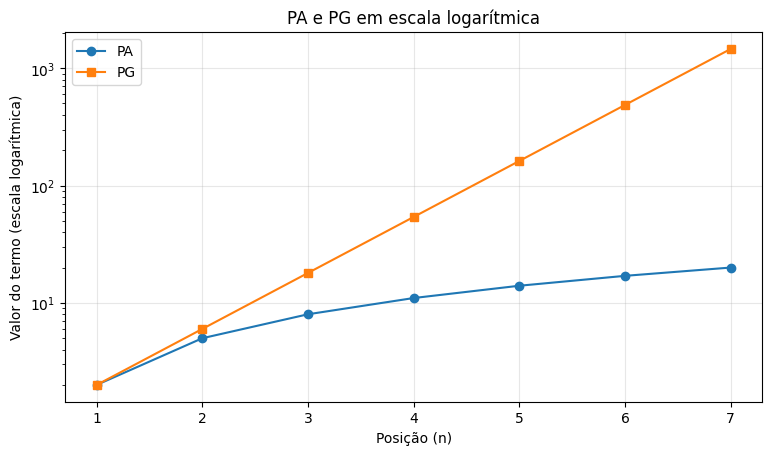

In [7]:
# @title
n = np.arange(1, 8)
termos_pa = 2 + (n - 1) * 3
termos_pg = 2 * 3 ** (n - 1)

plt.figure()
plt.plot(n, termos_pa, marker="o", label="PA")
plt.plot(n, termos_pg, marker="s", label="PG")
plt.yscale("log")
plt.xticks(n)
plt.xlabel("Posição (n)")
plt.ylabel("Valor do termo (escala logarítmica)")
plt.title("PA e PG em escala logarítmica")
plt.legend()
plt.show()

## 5. Soma dos primeiros termos de uma PG

Quando $q\neq1$, a soma dos $n$ primeiros termos de uma PG finita é:

$$
\boxed{S_n=a_1\cdot\frac{q^n-1}{q-1}}
$$

Uma forma equivalente é $S_n=a_1\cdot\frac{1-q^n}{1-q}$. A segunda forma é útil quando $q<1$.

Se $q=1$, todos os termos são iguais a $a_1$, então:

$$
\boxed{S_n=n\cdot a_1}
$$

### Exemplo

Na PG $(2,6,18,54)$, temos $a_1=2$, $q=3$ e $n=4$:

$$
S_4=2\cdot\frac{3^4-1}{3-1}
=2\cdot\frac{80}{2}=\boxed{80}
$$

Vamos conferir o resultado somando os termos diretamente e visualizar a soma acumulada.

In [8]:
# @title
a1 = 2
q = 3
quantidade = 4

n = np.arange(1, quantidade + 1)
termos = a1 * q ** (n - 1)
somas_acumuladas = np.cumsum(termos)

if q == 1:
    soma_formula = quantidade * a1
else:
    soma_formula = a1 * (q ** quantidade - 1) / (q - 1)

print("Termos:", termos.tolist())
print("Somas acumuladas:", somas_acumuladas.tolist())
print("Soma pela fórmula:", int(soma_formula))
print("Soma direta:", int(sum(termos)))

Termos: [2, 6, 18, 54]
Somas acumuladas: [2, 8, 26, 80]
Soma pela fórmula: 80
Soma direta: 80


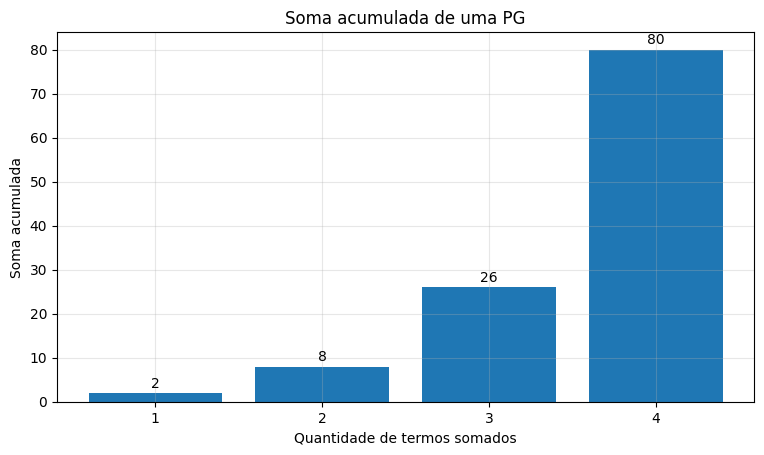

In [9]:
# @title
plt.figure()
plt.bar(n, somas_acumuladas)
for pos, soma in zip(n, somas_acumuladas):
    plt.annotate(str(int(soma)), (pos, soma), xytext=(0, 4),
                 textcoords="offset points", ha="center")
plt.xticks(n)
plt.xlabel("Quantidade de termos somados")
plt.ylabel("Soma acumulada")
plt.title("Soma acumulada de uma PG")
plt.show()

## 6. Razão entre zero e um: a PG pode se aproximar de zero

Considere a PG $(64,32,16,8,4,\ldots)$, cuja razão é $q=\frac12$.

Cada termo é metade do anterior. Os termos diminuem e se aproximam de zero, mas não chegam a zero se continuarmos a multiplicar números positivos por $\frac12$.

Esse comportamento é chamado de **convergência para zero**. Ele ocorre em uma PG com primeiro termo finito quando $|q|<1$.

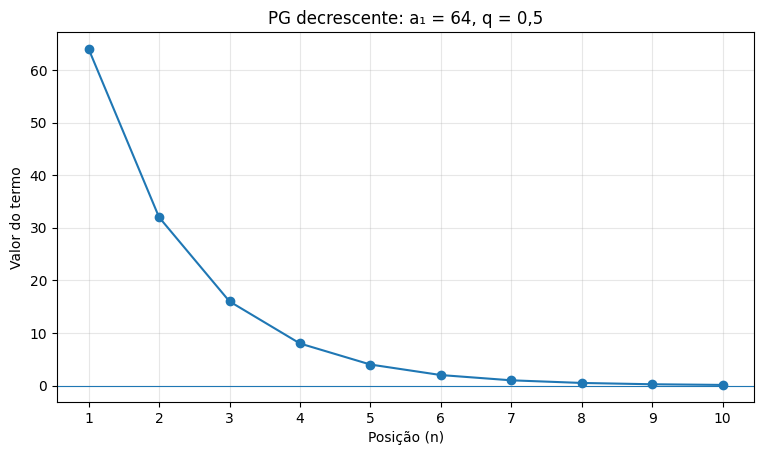

Termo da posição 10: 0.125


In [10]:
# @title
a1 = 64
q = 0.5
n = np.arange(1, 11)
valores = a1 * q ** (n - 1)

plt.figure()
plt.plot(n, valores, marker="o")
plt.axhline(0, linewidth=0.8)
plt.xticks(n)
plt.xlabel("Posição (n)")
plt.ylabel("Valor do termo")
plt.title("PG decrescente: a₁ = 64, q = 0,5")
plt.show()

print("Termo da posição 10:", valores[-1])

## 7. Exercício prático

Considere a PG:

$$
(5, 10, 20, 40, \ldots)
$$

Antes de executar o código, tente responder:

1. Qual é a razão?
2. Qual é o 8.º termo?
3. Qual é a soma dos 8 primeiros termos?

Use a célula abaixo para conferir os resultados.

In [11]:
# @title
a1 = 5
q = 2
n = 8

an = a1 * q ** (n - 1)
termos = [a1 * q ** i for i in range(n)]
soma = sum(termos)

print(f"Razão: {q}")
print(f"8.º termo: {an}")
print(f"Soma dos 8 primeiros termos: {soma}")
print("Sequência:", termos)

Razão: 2
8.º termo: 640
Soma dos 8 primeiros termos: 1275
Sequência: [5, 10, 20, 40, 80, 160, 320, 640]


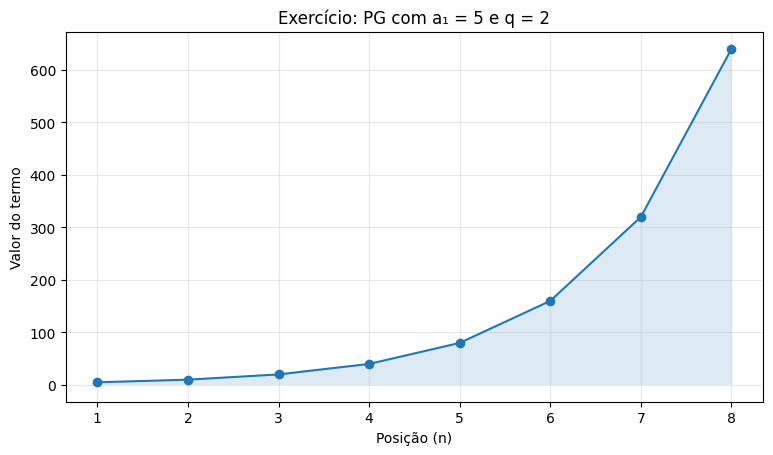

In [12]:
# @title
posicoes = np.arange(1, n + 1)

plt.figure()
plt.plot(posicoes, termos, marker="o")
plt.fill_between(posicoes, termos, alpha=0.15)
plt.xticks(posicoes)
plt.xlabel("Posição (n)")
plt.ylabel("Valor do termo")
plt.title("Exercício: PG com a₁ = 5 e q = 2")
plt.show()

## 8. Resumo: PA × PG

| Conceito | Progressão Aritmética (PA) | Progressão Geométrica (PG) |
|---|---|---|
| Regra | Soma uma diferença fixa | Multiplica por um fator fixo |
| Razão | $r=a_n-a_{n-1}$ | $q=\frac{a_n}{a_{n-1}}$, se o anterior não for zero |
| Termo geral | $a_n=a_1+(n-1)r$ | $a_n=a_1q^{n-1}$ |
| Soma dos $n$ termos | $S_n=\frac{(a_1+a_n)n}{2}$ | $S_n=a_1\frac{q^n-1}{q-1}$, se $q\neq1$ |
| Exemplo | $2,5,8,11,\ldots$ | $2,6,18,54,\ldots$ |

### Para guardar

- **PA:** a diferença entre termos consecutivos é constante.
- **PG:** o quociente entre termos consecutivos é constante, quando a divisão está definida.
- A fórmula do termo geral permite encontrar um termo sem listar os anteriores.
- O gráfico ajuda a observar o comportamento, mas a fórmula confirma os cálculos.